# Lesson 10. Where does a point go when the camera turns?

[Course plan](../../README.md)

A wire triangle stands on a table. The camera slides right, and the triangle ends up on its left. The wire has the same length and occupies the same patch of table. What moved was the place from which we measure “to the right.” Before drawing pixels, we need a way to keep track of that reference.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "geometry3d.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import geometry3d as geo
import geometry_demos as demos
np.set_printoptions(precision=4, suppress=True)

## 1. The triangle in two windows

Both drawings are overhead views. Horizontal position is $x$ and depth is $z$. The third coordinate, $y$, still enters the calculation. In the right-hand view the grid always starts at the camera. The orange vertex can move on its own. Two other corners are fixed to a common frame. “Point x” moves just the vertex and changes the shape. “Object x” shifts the entire frame without bending it. “Camera x” moves the measuring origin. “Camera yaw” turns its axes. A short green line shows the camera's forward direction.

The right-hand coordinates start at $(1,1,4)$. Suppose “Object x” and “Camera x” both increase from 1 to 2. On the left, the frame and camera travel one meter together. On the right, all three vertices stay put. The world positions have changed, yet a picture taken by this camera would look the same.

In [2]:
display(demos.geometry_lab(10, "en"))

## 2. Three numbers, three origins

Lengths in this scene are in meters. The camera axes point right ($x$), down ($y$) and forward ($z$). This choice makes increasing $y$ move a pixel down the image later. The triple $(1,1,4)$ measures one meter right, one down and four forward from a particular origin. A negative $x$ means the same distance to the left.

The selected vertex starts at $p=(1,1,4)$ in the frame attached to the triangle. The frame's own origin lies at world point $O=(1,0,0)$. The axes are parallel for now. Adding matching components gives the world position:

$$
P=O+p=(1+1,\;0+1,\;0+4)=(2,1,4).
$$

A third origin is the camera center $C=(1,0,0)$ in the world. The **displacement** $d$ runs from that center to the vertex. It has a length and a direction. Subtracting the starting point from the endpoint gives it:

$$
d=P-C=(2-1,\;1-0,\;4-0)=(1,1,4).
$$

If the camera reaches $C=(2,0,0)$, the first component becomes $2-2=0$. The vertex is straight ahead horizontally, although its world $x$ is still 2. Translating every point together preserves the displacement between any pair because the common addition cancels in the subtraction.

In [3]:
p = np.array([1., 1., 4.])
O = np.array([1., 0., 0.])
C = np.array([1., 0., 0.])
P = O + p
print("P =", P, "   P-C =", P - C)
assert np.array_equal((P + [1, 0, 0]) - (C + [1, 0, 0]), P - C)

P = [2. 1. 4.]    P-C = [1. 1. 4.]


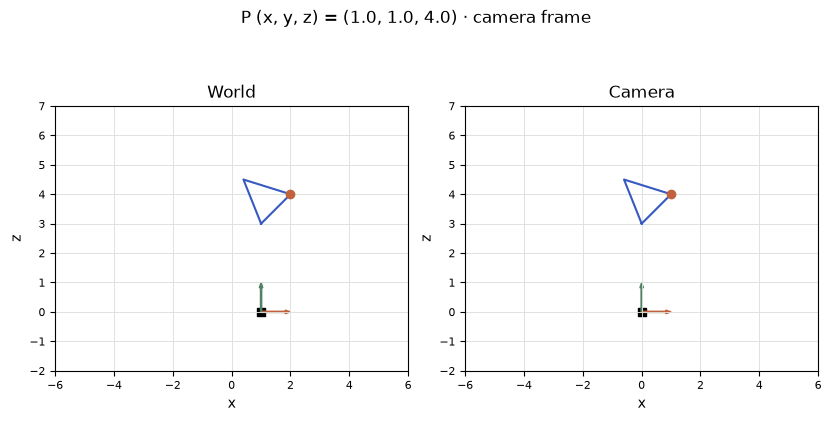

In [4]:
fig = demos.frame_figure("en")
plt.show()

## 3. Reading a direction along a different axis

The world axes stay put. The camera turns $30^\circ$ to the right about its vertical axis. Its unit directions, written in world coordinates, now read

$$
r=(0.866,0,-0.5),\quad b=(0,1,0),\quad f=(0.5,0,0.866).
$$

The letters stand for right, down and forward. A unit direction has length 1. For $f$, the sum of squares is about $0.5^2+0.866^2=1$. The value 0.866 is rounded here and below. Turning the original direction keeps its length. The numbers 0.5 and 0.866 are the sine and cosine of the angle, the sideways and forward fractions of a unit arrow turned away from straight ahead.

How much of $d=(1,1,4)$ lies along the new right axis? The first meter in world $x$ contributes $0.866$ m. The meter in world $y$ contributes zero. Four meters in world $z$ contribute $4\cdot(-0.5)=-2$ m. Together that gives $0.866+0-2=-1.134$ m. This sum of matching products is a **dot product**. With a unit axis it measures signed length along that axis.

The down component is $0\cdot1+1\cdot1+0\cdot4=1$. The forward component is $0.5\cdot1+0\cdot1+0.866\cdot4=3.964$. After the turn the vertex lies left, down and still in front. Its overhead position is just the intersection of $x=-1.134$ and $z=3.964$. The wire and its distance from the camera haven't changed. What changed was the orientation of the three rulers.

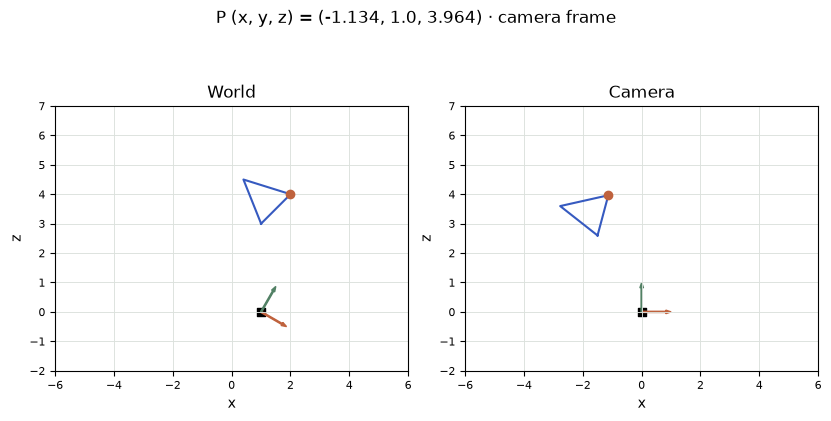

In [5]:
fig = demos.frame_figure("en", yaw=30)
plt.show()

## 4. Three rulers in one matrix

Writing the axes as columns gives $B=[r\ b\ f]$. A column contains three numbers from top to bottom. To compute all three dot products at once we need those axes as **rows**. The superscript $\mathsf T$ means transpose, swapping rows with columns.

$$
p_c=B^{\mathsf T}(P-C)
=\begin{bmatrix}0.866&0&-0.5\\0&1&0\\0.5&0&0.866\end{bmatrix}
\begin{bmatrix}1\\1\\4\end{bmatrix}
\approx\begin{bmatrix}-1.134\\1\\3.964\end{bmatrix}.
$$

Multiplying a matrix by a column amounts to the three familiar calculations in order. To go back we add three world arrows: $P=C+r\,p_{c,x}+b\,p_{c,y}+f\,p_{c,z}=C+Bp_c$. Transposing undoes the rotation because the axes are perpendicular and have unit length. An axis dotted with itself gives 1 and dotted with its neighbor gives 0. Consequently $B^{\mathsf T}B$ has ones on its diagonal and zeros everywhere else.

Turning the object's own frame adds a step. Matrix $A$ takes object axes into the world. A $90^\circ$ turn of the frame about $z$ carries local point $(1,1,4)$ to $(-1,1,4)$. Translation by $O=(1,0,0)$ gives world point $(0,1,4)$. Adding $O$ before turning would give $(-1,2,4)$, since the turn then carries the frame origin along too. The whole chain $p_c=B^{\mathsf T}(O+Ap-C)$ reads from the inside out.

In [6]:
angle = np.deg2rad(30)
c, s = np.cos(angle), np.sin(angle)
B = np.array([[c,0,s], [0,1,0], [-s,0,c]])
pc = geo.world_to_camera(P, C, B)
print("B.T =\n", B.T, "\np_camera =", pc)
np.testing.assert_allclose(C + B @ pc, P)
np.testing.assert_allclose(B.T @ B, np.eye(3), atol=1e-14)

B.T =
 [[ 0.866  0.    -0.5  ]
 [ 0.     1.     0.   ]
 [ 0.5    0.     0.866]] 
p_camera = [-1.134   1.      3.9641]


In [7]:
A = np.array([[0,-1,0], [1,0,0], [0,0,1]])
print("O+A@p =", O + A @ p, "    A@(O+p) =", A @ (O+p))
print("world distance =", np.linalg.norm(P-C), "  camera distance =", np.linalg.norm(pc))

O+A@p = [0. 1. 4.]     A@(O+p) = [-1.  2.  4.]
world distance = 4.242640687119285   camera distance = 4.242640687119285


## 5. What stays in the drawing?

**An experiment.** The camera initially looks straight ahead. What happens to the relative position if the camera moves one meter right and the vertex moves two?

<details>
<summary>Working it out</summary>

The new world $x$ of the vertex is $2+2=4$. The camera reaches $1+1=2$. The right-hand view now reads $4-2=2$ instead of 1. The other coordinates remain 1 and 4. The rightward component grew by the difference in the displacements, $2-1=1$ m.

</details>

**Another angle.** Which turn puts the initial direction $(1,1,4)$ exactly in the horizontal middle?

<details>
<summary>Working it out</summary>

The new right component must satisfy $1\cos\theta-4\sin\theta=0$. Dividing by $4\cos\theta$ gives $\tan\theta=1/4$. Tangent is the ratio of the sideways leg of the triangle to the forward leg. Its inverse takes us back to an angle, about $14.04^\circ$. At the nearest whole degree, $14^\circ$, around $0.003$ m remains. The vertical coordinate is still 1, so the centering is horizontal only.

</details>